# 3 STATISTICAL ANALYSIS

**Project:** Irish Milk Supply: Growth, Seasonality and Forecasting

**Author:** Temuulen Bulgan

### Purpose of this notebook
This notebook describes the long-term trend and seasonal pattern of Irish milk supply, tests whether growth changed after EU milk quotas ended in April 2015, shows where the extra milk went, and looks at changes in fat and protein content.

### Input
The `dairy` database in SQL Server, loaded in notebook 2.

### Output
Charts saved in the `figures/` folder and the results of a linear regression.

## Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from sqlalchemy import create_engine

#### Connect to the database

In [2]:
# Connection to the dairy database on this computer
engine = create_engine(
    "mssql+pyodbc://@localhost/dairy"
    "?driver=ODBC+Driver+18+for+SQL+Server"
    "&trusted_connection=yes"
    "&TrustServerCertificate=yes",
)

# Test the connection: list the tables in the dairy database
pd.read_sql("SELECT name FROM sys.tables ORDER BY name", engine)

,name
0,dim_date
1,dim_measure
2,fact_monthly


## 1. Load the data

All monthly values are read from the database, with the year, month and quota period from `dim_date`.

In [3]:
# Every monthly value, with its date details from dim_date
query = """
    SELECT
        f.date_key,
        d.[year],
        d.[month],
        d.quota_period,
        f.measure_code,
        f.value
    FROM fact_monthly AS f
    JOIN dim_date AS d
        ON f.date_key = d.date_key
    ORDER BY f.measure_code, f.date_key;
"""

data = pd.read_sql(query, engine, parse_dates=["date_key"])

print(data.shape)
print(data.dtypes)
display(data.head(3))

(4538, 6)
date_key        datetime64[s]
year                    int64
month                   int64
quota_period              str
measure_code              str
value                 float64
dtype: object


,date_key,year,month,quota_period,measure_code,value
0,1980-01-01,1980,1,pre-quota,butter_kt,1.8
1,1980-02-01,1980,2,pre-quota,butter_kt,4.4
2,1980-03-01,1980,3,pre-quota,butter_kt,8.7


The data has 4,538 rows, one per month and measure, the same as `fact_monthly` in the database.

### 1.1 Reshape to one column per measure

The database stores the data in long format: one row per month and measure. For the analysis it is easier to have one row per month and one column per measure. `pivot` does this. It is the reverse of `melt`, which turned the wide table into long format in notebook 2.

In [4]:
# Long format to wide format: one row per month, one column per measure
monthly = data.pivot(
    index=["date_key", "year", "month", "quota_period"],
    columns="measure_code",
    values="value",
)

# Move the index columns back into normal columns
monthly = monthly.reset_index()

# Remove the leftover name "measure_code" from the column header
monthly.columns.name = None

monthly.shape

(620, 12)

In [5]:
# Non-missing cells per measure
measure_columns = data["measure_code"].unique()
monthly[measure_columns].count()

butter_kt          560
canada_total_ml    606
cheese_kt          552
fat_pct            560
intake_ml          620
liquid_sales_ml    560
protein_pct        560
smp_kt             520
dtype: int64

In [6]:
# Every row in data fills exactly one cell in monthly
monthly[measure_columns].count().sum() == len(data)

np.True_

The wide table has one row per month from January 1975 to August 2026. Only milk intake is complete. The other measures start later or have gaps, shown as `NaN`. The non-missing cells add up to the number of rows in the database, so nothing was lost or duplicated.

## 2. Long-term trend since 1975

Monthly intake is very seasonal, so the long-term trend is easier to see in yearly totals. A yearly total is only correct when all 12 months are present. 2026 has data up to August only, so incomplete years are left out.

In [7]:
# Yearly intake total and number of months with data
yearly = monthly.groupby("year").agg(
    intake_ml=("intake_ml", "sum"),
    months=("intake_ml", "count"),
)

# Years without all 12 months
yearly[yearly["months"] < 12]

,intake_ml,months
year,,
2026,6433.4,8


In [8]:
# Keep complete years only
complete_years = yearly[yearly["months"] == 12]

print(complete_years.shape)
print(complete_years.index.min(), complete_years.index.max())

(51, 2)
1975 2025


Only 2026 is incomplete, with 8 months. The year 2026 has not finished yet, so its total covers January to August only. It would look like a large drop in intake, so it is left out. The 51 complete years from 1975 to 2025 match the result of SQL Query 1.

### 2.1 Yearly milk intake, 1975–2025

The dashed lines mark the start of EU milk quotas (April 1984) and their end (April 2015).

#### Background: EU milk quotas

- The EU introduced milk quotas in April 1984 to limit over-production of milk across the member states.
- In 2003 the EU agreed to end quotas in 2015. From 2009 to 2013, quotas were raised by about 1% a year to prepare farmers for the end of quotas.
- Quotas ended on 1 April 2015.

Source: [Agriland, "Milk quotas to end within days, but why were they introduced?" (2015)](https://www.agriland.co.uk/farming-news/end-of-milk-quotas-why-dairy-quotas-were-introduced/); [European Commission JRC, Regional economic analysis of milk quota reform in the EU (2009)](https://publications.jrc.ec.europa.eu/repository/bitstream/JRC53116/jrc53116.pdf)

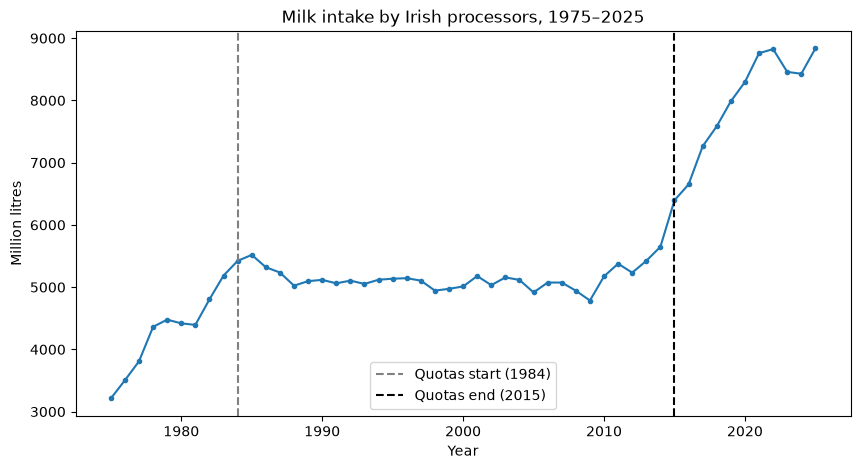

In [9]:
# Line chart of yearly intake
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(complete_years.index, complete_years["intake_ml"], marker="o", markersize=3)

# Start and end of milk quotas
ax.axvline(1984, color="grey", linestyle="--", label="Quotas start (1984)")
ax.axvline(2015, color="black", linestyle="--", label="Quotas end (2015)")

# Titles, labels and legend
ax.set_title("Milk intake by Irish processors, 1975–2025")
ax.set_xlabel("Year")
ax.set_ylabel("Million litres")
ax.legend()

# Save the chart and show it
fig.savefig("../figures/03_annual_intake.png", dpi=150, bbox_inches="tight")
plt.show()

Intake rose until the early 1980s and then stayed almost flat while quotas were in place. After quotas ended in 2015, intake rose sharply. It fell in 2023.

## 3. Effect of the quota end: did growth speed up after 2015?

The chart shows faster growth after quotas ended. A regression measures how much faster, with a confidence interval. The model fits a straight trend to log intake for the quota years and lets the slope change after 2015. The slope of log intake is roughly the growth rate per year.

### 3.1 Prepare the data

The data starts in 1985, the first full year under quotas. `years_after_2015` is 0 up to 2015 and then counts 1, 2, 3, … It lets the trend bend after 2015.

In [10]:
# Year as a normal column, so the regression formula can use it
trend_data = complete_years.reset_index()

# Keep complete years from 1985, the first full quota year
trend_data = trend_data[trend_data["year"] >= 1985].copy()

# Log of yearly intake: its slope is roughly the growth rate per year
trend_data["log_intake"] = np.log(trend_data["intake_ml"])

# Years since 2015, and 0 for 2015 and earlier
trend_data["years_after_2015"] = (trend_data["year"] - 2015).clip(lower=0)

trend_data.shape

(41, 5)

In [11]:
# Years around 2015, to check where years_after_2015 starts counting
trend_data[trend_data["year"].between(2013, 2017)]

,year,intake_ml,months,log_intake,years_after_2015
38,2013,5422.7,12,8.598349,0
39,2014,5648.6,12,8.639163,0
40,2015,6395.3,12,8.763319,0
41,2016,6651.0,12,8.802522,1
42,2017,7262.8,12,8.890521,2


The table has 41 complete years, 1985–2025. `years_after_2015` is 0 up to 2015 and starts counting in 2016.

### 3.2 Fit the regression

The model is `log_intake = b0 + b1 × year + b2 × years_after_2015`. `b1` is the yearly growth under quotas. `b2` is the change in yearly growth after 2015.

In [12]:
# Fit the regression: trend for the quota years plus a change in slope after 2015
model = smf.ols("log_intake ~ year + years_after_2015", data=trend_data)
results = model.fit()

print(results.summary())

                            OLS Regression Results                            
Dep. Variable:             log_intake   R-squared:                       0.867
Model:                            OLS   Adj. R-squared:                  0.860
Method:                 Least Squares   F-statistic:                     124.0
Date:                Fri, 16 Oct 2026   Prob (F-statistic):           2.21e-17
Time:                        12:48:08   Log-Likelihood:                 48.858
No. Observations:                  41   AIC:                            -91.72
Df Residuals:                      38   BIC:                            -86.57
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           -0.0898      2.821  

Under quotas, log intake grew by about 0.004 a year, about 0.4% a year. After 2015 the slope was about 0.054 higher, so growth was about 6% a year. The Durbin–Watson statistic is 0.26, far below 2. This shows strong autocorrelation in the residuals, so the standard errors and confidence intervals in this table are too small. The next section checks this and corrects the standard errors.

### 3.3 Check the residuals

A residual is the gap between actual log intake and the fitted line. If the years are independent, the residuals jump above and below zero at random. Long runs on the same side of zero mean the residuals are autocorrelated.

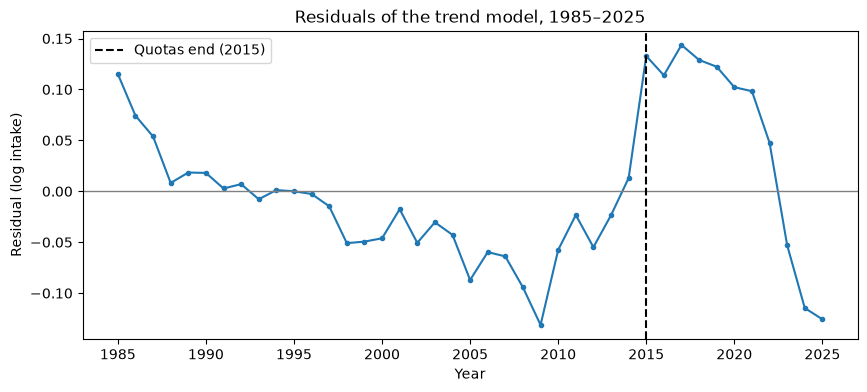

In [13]:
# Residuals: actual log intake minus the fitted line
residuals = results.resid

# Residuals by year, with a zero line and the end of quotas
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(trend_data["year"], residuals, marker="o", markersize=3)
ax.axhline(0, color="grey", linewidth=1)
ax.axvline(2015, color="black", linestyle="--", label="Quotas end (2015)")

# Titles, labels and legend
ax.set_title("Residuals of the trend model, 1985–2025")
ax.set_xlabel("Year")
ax.set_ylabel("Residual (log intake)")
ax.legend()

# Save the chart and show it
fig.savefig("../figures/03_trend_residuals.png", dpi=150, bbox_inches="tight")
plt.show()

The residuals stay on the same side of zero for several years in a row instead of jumping around at random. This matches the low Durbin–Watson statistic: the years are not independent, so the standard errors from the first fit are too small.

### 3.4 Refit with Newey–West standard errors

Newey–West (HAC) standard errors allow for autocorrelated residuals. The coefficients stay the same. Only the standard errors, p-values and confidence intervals change.

In [14]:
# Same model, with standard errors that allow for autocorrelation
results_hac = model.fit(cov_type="HAC", cov_kwds={"maxlags": 3})

print(results_hac.summary())

                            OLS Regression Results                            
Dep. Variable:             log_intake   R-squared:                       0.867
Model:                            OLS   Adj. R-squared:                  0.860
Method:                 Least Squares   F-statistic:                     39.82
Date:                Fri, 16 Oct 2026   Prob (F-statistic):           4.74e-10
Time:                        12:48:08   Log-Likelihood:                 48.858
No. Observations:                  41   AIC:                            -91.72
Df Residuals:                      38   BIC:                            -86.57
Df Model:                           2                                         
Covariance Type:                  HAC                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           -0.0898      4.774  

The coefficients are the same as in 3.2, but the standard errors are about 1.7 times larger. Under quotas, growth of about 0.4% a year is no longer significant at the 5% level (p = 0.07), so intake was close to flat. After 2015, growth was 3.3 to 7.4 percentage points a year higher (95% interval), and this change is still clearly significant.

### 3.5 Sensitivity check: bend at 2013

Intake may have started rising before quotas ended, during the 1% yearly quota increases. This check moves the bend to 2013. 2015 stays the main model because it is the policy date. If the change in slope is still clearly positive with a 2013 bend, the result does not depend on the exact year.

In [15]:
# Years since 2013, and 0 for 2013 and earlier
trend_data["years_after_2013"] = (trend_data["year"] - 2013).clip(lower=0)

# Same model with the bend at 2013, Newey-West standard errors
model_2013 = smf.ols("log_intake ~ year + years_after_2013", data=trend_data)
results_2013 = model_2013.fit(cov_type="HAC", cov_kwds={"maxlags": 3})

# Coefficient table only
print(results_2013.summary().tables[1])
print("R-squared:", round(results_2013.rsquared, 3))

                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            4.7728      3.117      1.531      0.126      -1.337      10.882
year                 0.0019      0.002      1.211      0.226      -0.001       0.005
years_after_2013     0.0505      0.007      7.239      0.000       0.037       0.064
R-squared: 0.926


With the bend at 2013, the change in slope is about 0.051, with a 95% interval of 0.037 to 0.064, so it is still clearly positive. The fit is better than with the 2015 bend (R-squared 0.93 against 0.87). This suggests intake started to rise a little before quotas ended, during the years of quota increases. The main result does not depend on the exact year: growth was close to flat under quotas and about 5 percentage points a year faster afterwards.

### 3.6 Summary

- Under quotas (1985 to 2015), yearly intake was close to flat: growth of about 0.4% a year, not significantly different from zero.
- After quotas ended, growth was about 5 percentage points a year faster (95% interval 3.3 to 7.4, Newey–West standard errors).
- The residuals are strongly autocorrelated, so ordinary standard errors were too small. Newey–West standard errors correct for this.
- Moving the bend to 2013 gives the same conclusion and a better fit, so intake started to rise a little before quotas formally ended.

## 4. Where the extra milk went

After quotas ended, much more milk was collected. This section compares the change in liquid milk sales (drinking milk) with the change in butter and cheese output, from 2014 (the last full year under quotas) to 2025.

### 4.1 Yearly totals by product

In [16]:
# Measures to compare
product_columns = ["intake_ml", "liquid_sales_ml", "butter_kt", "cheese_kt"]

# Yearly totals, only when all 12 months are present
yearly_products = monthly.groupby("year")[product_columns].sum(min_count=12)

yearly_products.loc[[2014, 2025]].round(1)

,intake_ml,liquid_sales_ml,butter_kt,cheese_kt
year,,,,
2014,5648.6,482.2,166.3,188.4
2025,8835.3,486.0,293.3,285.8


From 2014 to 2025, liquid milk sales stayed almost the same, while butter and cheese output rose a lot.

### 4.2 Percent change, 2014 to 2025

The products are measured in different units (million litres and thousand tonnes), so they are compared by percent change.

In [17]:
# Last full quota year and last complete year
start_year = 2014
end_year = 2025

# Percent change from start_year to end_year for each product
start_values = yearly_products.loc[start_year]
end_values = yearly_products.loc[end_year]
percent_change = (end_values / start_values - 1) * 100

percent_change.round(1)

intake_ml          56.4
liquid_sales_ml     0.8
butter_kt          76.4
cheese_kt          51.7
dtype: float64

From 2014 to 2025, intake rose by about 56%. Liquid milk sales rose by less than 1%. Butter output rose by about 76% and cheese output by about 52%. The extra milk went into butter and cheese, not into drinking milk.

### 4.3 Chart of the percent changes

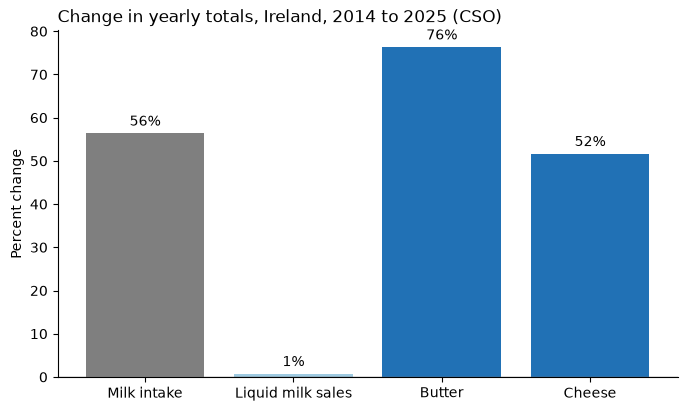

In [18]:
# Readable names for the chart
chart_labels = {
    "intake_ml": "Milk intake",
    "liquid_sales_ml": "Liquid milk sales",
    "butter_kt": "Butter",
    "cheese_kt": "Cheese",
}
chart_data = percent_change.rename(index=chart_labels)

# Colours by role: intake as the grey reference, products in blue
colour_map = {
    "Milk intake": "#7f7f7f",
    "Liquid milk sales": "#9ecae1",
    "Butter": "#2171b5",
    "Cheese": "#2171b5",
}
bar_colours = [colour_map[name] for name in chart_data.index]

# Bar chart with the value on top of each bar
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(chart_data.index, chart_data.values, color=bar_colours)
ax.bar_label(bars, fmt="%.0f%%", padding=3)
ax.axhline(0, color="grey", linewidth=1)

# Detailed title and labels
ax.set_title(
    f"Change in yearly totals, Ireland, {start_year} to {end_year} (CSO)",
    loc="left",
)
ax.set_ylabel("Percent change")

# Remove the top and right frame lines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Save the chart and show it
fig.savefig("../figures/03_product_change.png", dpi=150, bbox_inches="tight")
plt.show()

Butter and cheese grew at about the same rate as intake or faster, while liquid milk sales hardly changed. The extra milk after quotas went mainly into butter and cheese.

## 5. Seasonal pattern: Ireland vs Canada

Irish dairy farming is grass-based, so most cows calve in spring and milk supply follows grass growth. Canada is used as a comparison. This section compares the average monthly pattern in both countries.

### 5.1 Average intake by calendar month, 2016–2025

The averages use the ten complete years after quotas ended. The values reflect current supply levels, and every month has the same number of years.

In [19]:
# Ten complete post-quota years
recent = monthly[monthly["year"].between(2016, 2025)]

# Average for each calendar month, Ireland and Canada
monthly_profile = recent.groupby("month")[["intake_ml", "canada_total_ml"]].mean()

monthly_profile.round(1)

,intake_ml,canada_total_ml
month,,
1,166.6,784.8
2,327.0,722.6
3,729.6,792.8
4,955.6,768.3
5,1090.4,795.6
6,1001.0,771.2
7,947.1,792.2
8,859.8,792.1
9,727.4,765.4


Irish intake is highest in May and lowest in January. May is about 6.5 times January. Canadian milk supply is almost the same every month. The results match SQL Queries 3 and 5.

### 5.2 Chart of the monthly patterns

Each month is shown as a percentage of the country's own monthly average (average = 100). This compares the shape of the seasons, not the size of the two dairy sectors.

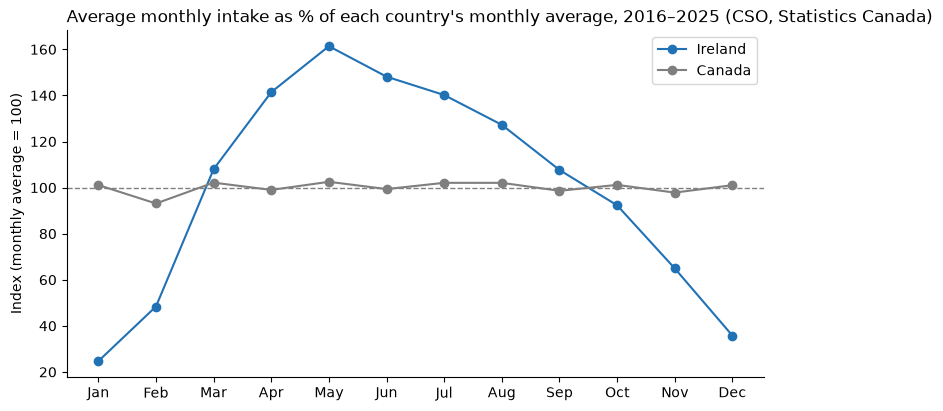

In [20]:
# Each month as a percent of the country's own monthly average
profile_index = monthly_profile / monthly_profile.mean() * 100

# Month names for the x-axis
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# Line chart of both countries
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(month_names, profile_index["intake_ml"], marker="o", color="#2171b5", label="Ireland")
ax.plot(month_names, profile_index["canada_total_ml"], marker="o", color="#7f7f7f", label="Canada")
ax.axhline(100, color="grey", linestyle="--", linewidth=1)

# Detailed title and labels
ax.set_title(
    "Average monthly intake as % of each country's monthly average, 2016–2025 (CSO, Statistics Canada)",
    loc="left",
)
ax.set_ylabel("Index (monthly average = 100)")
ax.legend()

# Remove the top and right frame lines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Save the chart and show it
fig.savefig("../figures/03_seasonality_ie_ca.png", dpi=150, bbox_inches="tight")
plt.show()

Irish intake in May is about 60% above an average month, and in January about 75% below it. Canadian supply stays within a few percent of its average all year.

### 5.3 What the seasonal pattern means for processing capacity

A processing plant must be big enough for the busiest month. In the other months part of it stands idle. The average month divided by the peak month shows how much of that capacity is used on average across the year.

In [21]:
# Average month and peak month for each country
average_month = monthly_profile.mean()
peak_month = monthly_profile.max()

# Average use of capacity sized for the peak month, in percent
capacity_use = average_month / peak_month * 100

capacity_use.round(1)

intake_ml          62.0
canada_total_ml    97.6
dtype: float64

If plants are sized for the peak month, Irish plants use about 62% of their capacity in an average month, against about 98% in Canada. This is a simple indicator: it ignores storage and moving milk between plants. It shows why seasonality is costly for Irish processors: much of the capacity is needed only in spring and early summer.

## 6. Milk composition: fat and protein

Fat and protein content decide how much butter and cheese can be made from each litre. This section checks how they changed over time.

### 6.1 Yearly fat and protein, weighted by volume

Fat and protein data start in January 1980. A simple average of the 12 monthly values would give January the same weight as May, although May has about six times as much milk. The yearly values are therefore weighted by intake: each month counts in proportion to its volume.

In [22]:
# Complete years with fat and protein data
quality = monthly[monthly["year"].between(1980, 2025)].copy()

# Missing months in the period
quality[["fat_pct", "protein_pct"]].isna().sum()

fat_pct        0
protein_pct    0
dtype: int64

In [23]:
# Percent multiplied by volume, so heavy months count more
quality["fat_x_intake"] = quality["fat_pct"] * quality["intake_ml"]
quality["protein_x_intake"] = quality["protein_pct"] * quality["intake_ml"]

# Yearly sums
yearly_quality = quality.groupby("year")[["intake_ml", "fat_x_intake", "protein_x_intake"]].sum()

# Weighted yearly averages
yearly_quality["fat_pct"] = yearly_quality["fat_x_intake"] / yearly_quality["intake_ml"]
yearly_quality["protein_pct"] = yearly_quality["protein_x_intake"] / yearly_quality["intake_ml"]

yearly_quality.loc[[1980, 2025], ["fat_pct", "protein_pct"]].round(2)

,fat_pct,protein_pct
year,,
1980,3.49,3.18
2025,4.34,3.61


There are no missing months from 1980 to 2025. Weighted by volume, fat content rose from about 3.5% in 1980 to about 4.3% in 2025, and protein from about 3.2% to about 3.6%.

### 6.2 Chart of fat and protein over time

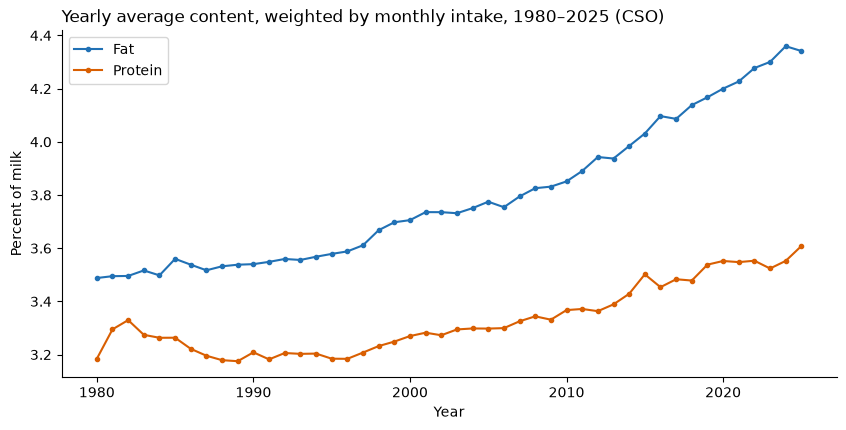

In [24]:
# Yearly weighted fat and protein
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(yearly_quality.index, yearly_quality["fat_pct"], marker="o", markersize=3,
        color="#2171b5", label="Fat")
ax.plot(yearly_quality.index, yearly_quality["protein_pct"], marker="o", markersize=3,
        color="#d95f02", label="Protein")

# Detailed title and labels
ax.set_title(
    "Yearly average content, weighted by monthly intake, 1980–2025 (CSO)",
    loc="left",
)
ax.set_xlabel("Year")
ax.set_ylabel("Percent of milk")
ax.legend()

# Remove the top and right frame lines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Save the chart and show it
fig.savefig("../figures/03_fat_protein.png", dpi=150, bbox_inches="tight")
plt.show()

Fat and protein content both rose from 1980 to 2025. Fat rose faster than protein. The rise is steady, with small year-to-year changes.

### 6.3 Fat and protein by calendar month, 2016–2025

Fat and protein also change within the year. This uses the same ten post-quota years as section 5.

In [25]:
# Average fat and protein for each calendar month
quality_profile = recent.groupby("month")[["fat_pct", "protein_pct"]].mean()

quality_profile.round(2)

,fat_pct,protein_pct
month,,
1,4.34,3.45
2,4.36,3.42
3,4.28,3.29
4,4.04,3.37
5,3.90,3.42
6,3.94,3.42
7,4.02,3.45
8,4.18,3.57
9,4.47,3.78


In [26]:
# Month with the lowest and the highest value
print("Lowest month:")
print(quality_profile.idxmin())
print("Highest month:")
print(quality_profile.idxmax())

Lowest month:
fat_pct        5
protein_pct    3
dtype: int64
Highest month:
fat_pct        11
protein_pct    10
dtype: int64


Fat and protein content are lowest in spring, when intake is highest, and highest in autumn, when intake is low. Fat is lowest in May (about 3.9%) and highest in November (about 4.9%).

### 6.4 Summary

- From 1980 to 2025, fat content rose from about 3.5% to about 4.3%, and protein from about 3.2% to about 3.6% (yearly averages weighted by intake).
- Fat rose faster than protein.
- Within the year, both are lowest in spring, when intake is highest, and highest in autumn, when intake is low.
- Richer milk means more butter and cheese from each litre. This adds to the effect of the higher volume after quotas ended.

## 7. Summary of findings

1. **Quotas held supply flat.** From 1985 to 2015, yearly intake grew by about 0.4% a year, not significantly different from zero. After quotas ended, growth was about 5 percentage points a year faster (95% interval 3.3 to 7.4, Newey–West standard errors). The rise started slightly before 2015, during the years of quota increases.
2. **The extra milk went into butter and cheese.** From 2014 to 2025, intake rose by about 56%. Butter output rose by about 76% and cheese by about 52%, while liquid milk sales hardly changed.
3. **Irish supply is very seasonal.** In 2016–2025, intake in May was about 6.5 times intake in January. Plants sized for the peak month would use about 62% of their capacity in an average month, compared with about 98% in Canada.
4. **Milk is getting richer.** Fat content rose from about 3.5% to about 4.3% between 1980 and 2025, and protein from about 3.2% to about 3.6%. Both are lowest in spring and highest in autumn.

**Limitations**
- National totals only, no regional or co-op detail.
- The regression uses 41 yearly values with strong autocorrelation, so the intervals are approximate.
- The capacity figure is a simple indicator: it ignores storage and moving milk between plants.
- Irish intake by processors and Canadian milk production are measured differently, so only the seasonal shapes are compared, not the levels.